# Deepfake Face Detection — Baseline Models

Trains the **two baseline detectors** for the capstone hybrid deepfake detector on the
**140k Real and Fake Faces** dataset.

| Baseline | Backbone | Strategy |
|---|---|---|
| 1 | **ConvNeXt-Tiny** | Full fine-tune |
| 2 | **CLIP ViT-L/14** | **Frozen** encoder → cached features → lightweight MLP head |



## Section 0 — Setup (device, install, Google Drive)

In [ ]:
# 0.1  Detect the runtime device (works on CPU OR GPU)
import torch
if torch.cuda.is_available():
    DEVICE = 'cuda'
    print('GPU runtime:', torch.cuda.get_device_name(0),
          '-> will use the FULL dataset.')
else:
    DEVICE = 'cpu'
    print('CPU runtime -> will use a SUBSET so it finishes in reasonable time.')
    print('   (Switch Runtime -> Change runtime type -> GPU for full training.)')
print('torch', torch.__version__, '| device:', DEVICE)


GPU runtime: Tesla T4 -> will use the FULL dataset.
torch 2.11.0+cu128 | device: cuda


In [ ]:
# 0.2  Install the extra libraries Colab doesn't ship with
!pip -q install timm transformers
import timm, transformers
print("timm", timm.__version__, "| transformers", transformers.__version__)


timm 1.0.29 | transformers 5.16.1


In [ ]:
# 0.3  Mount Google Drive (for persistent checkpoints / features / results)
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
# Everything the project writes lives here on your Drive:
PROJECT_DIR = Path('/content/drive/MyDrive/deepfake_capstone')
CKPT_DIR    = PROJECT_DIR / 'checkpoints'
FEATURE_DIR = PROJECT_DIR / 'features'
RESULTS_DIR = PROJECT_DIR / 'results'
LOG_DIR     = PROJECT_DIR / 'logs'
for d in (CKPT_DIR, FEATURE_DIR, RESULTS_DIR, LOG_DIR):
    d.mkdir(parents=True, exist_ok=True)
print("Project dir on Drive:", PROJECT_DIR)


Mounted at /content/drive
Project dir on Drive: /content/drive/MyDrive/deepfake_capstone


## Section 1 — Get the dataset

Downloads **140k Real and Fake Faces** from Kaggle. The 3.8 GB zip is cached on your
Drive, so it only downloads once; each session it is unzipped to Colab's fast local
disk (`/content`).

**You need a Kaggle API token:** kaggle.com → your profile → *Settings* → *API* →
*Create New Token* → downloads `kaggle.json`. Run the next cell and upload it.

In [ ]:
# 1.2  Download (cache zip on Drive) + unzip to local /content
import os, zipfile, time, shutil
from pathlib import Path

DRIVE_ZIP = PROJECT_DIR / 'archive.zip'              # cached copy on Drive
LOCAL_ZIP = Path('/content/archive.zip')
DATA_ROOT = Path('/content/real_vs_fake/real-vs-fake')  # unzipped, local

if not DRIVE_ZIP.exists():
    print("Downloading from Kaggle (~3.8 GB, one time)...")
    !kaggle datasets download -d xhlulu/140k-real-and-fake-faces -p /content
    shutil.move('/content/140k-real-and-fake-faces.zip', str(DRIVE_ZIP))
    print("Cached zip to Drive.")

if not DATA_ROOT.exists():
    print("Unzipping to local disk...")
    t=time.time()
    with zipfile.ZipFile(DRIVE_ZIP) as z:
        z.extractall('/content')
    print(f"Unzipped in {time.time()-t:.0f}s")

TRAIN_DIR, VALID_DIR, TEST_DIR = DATA_ROOT/'train', DATA_ROOT/'valid', DATA_ROOT/'test'
for s in (TRAIN_DIR, VALID_DIR, TEST_DIR):
    n = sum(1 for _ in s.rglob('*.jpg'))
    print(s.name, n, "images")


Unzipping to local disk...
Unzipped in 128s
train 100000 images
valid 20000 images
test 20000 images


## Section 2 — Config, dataset & dataloaders (shared by both models)

In [ ]:
# 2.1  Global config  (adapts to CPU vs GPU automatically)
import torch
# DEVICE was set in cell 0.1 ('cuda' or 'cpu').
IMG_SIZE = 224
SEED     = 42
CLASSES  = ['fake', 'real']         # fake=0, real=1
CLASS_TO_IDX = {'fake':0, 'real':1}
IMAGENET_MEAN = (0.485,0.456,0.406)
IMAGENET_STD  = (0.229,0.224,0.225)

# ---------------------------------------------------------------------------
# Set True to use the FULL dataset even on a CPU runtime.
#   WARNING: on CPU a full run is ~5-8 HOURS PER EPOCH and Colab disconnects a
#   CPU session before it finishes even a couple of epochs. It will NOT complete.
#   Only flip this on if you want to watch it run. For a real full run use a GPU
#   runtime (or your own 3050 Ti) -> ~11 min/epoch.
FORCE_FULL_ON_CPU = False
# ---------------------------------------------------------------------------

if DEVICE == 'cuda':
    # ---- full-scale settings (GPU) ----
    SUBSET_TRAIN = None       # None = use ALL images
    SUBSET_EVAL  = None
    NUM_EPOCHS   = 50
    CONVNEXT_BATCH = 64
    CLIP_EXTRACT_BATCH = 64
    NUM_WORKERS = 2
elif FORCE_FULL_ON_CPU:
    # ---- full dataset on CPU (impractically slow; you asked to try it) ----
    SUBSET_TRAIN = None
    SUBSET_EVAL  = None
    NUM_EPOCHS   = 50
    CONVNEXT_BATCH = 16
    CLIP_EXTRACT_BATCH = 16
    NUM_WORKERS = 2
    print('CPU + FULL dataset: expect ~5-8 h/epoch; Colab will likely disconnect '
          'before it finishes. Switch to a GPU runtime for a real full run.')
else:
    # ---- CPU pipeline-test settings (small so it actually finishes) ----
    SUBSET_TRAIN = 1500       # images sampled from the 100k train set
    SUBSET_EVAL  = 500        # images sampled from valid / test
    NUM_EPOCHS   = 5
    CONVNEXT_BATCH = 16
    CLIP_EXTRACT_BATCH = 16
    NUM_WORKERS = 2
    print('CPU mode: training on a subset '
          f'(train={SUBSET_TRAIN}, eval={SUBSET_EVAL}, epochs={NUM_EPOCHS}).')
    print('Set the runtime to GPU for the full run; these auto-switch to full scale.')

CLIP_HEAD_BATCH = 512
# Tag separates CPU-subset artifacts from full-GPU ones so they never mix.
TAG = 'full' if DEVICE == 'cuda' else 'cpu'
torch.manual_seed(SEED)
print('device', DEVICE, '| epochs', NUM_EPOCHS, '| train subset', SUBSET_TRAIN,
      '| artifact tag:', TAG)


device cuda | epochs 50 | train subset None | artifact tag: full


In [ ]:
# 2.2  Dataset + transforms
import random
from pathlib import Path
from PIL import Image, ImageFile
ImageFile.LOAD_TRUNCATED_IMAGES = True
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

IMG_EXTS = {'.jpg','.jpeg','.png','.bmp'}

def scan(split_dir):
    samples=[]
    for cls in CLASSES:
        d = Path(split_dir)/cls
        if d.exists():
            for p in d.iterdir():
                if p.suffix.lower() in IMG_EXTS:
                    samples.append((str(p), CLASS_TO_IDX[cls]))
    return samples

class FaceDataset(Dataset):
    def __init__(self, split_dir, transform, subset=None, seed=SEED):
        self.samples = scan(split_dir)
        if subset and subset < len(self.samples):
            self.samples = random.Random(seed).sample(self.samples, subset)
        self.transform = transform
    def __len__(self): return len(self.samples)
    def __getitem__(self, i):
        p, y = self.samples[i]
        return self.transform(Image.open(p).convert('RGB')), y

def tfm(train):
    ops = [transforms.Resize((IMG_SIZE,IMG_SIZE))]
    if train: ops.append(transforms.RandomHorizontalFlip())
    ops += [transforms.ToTensor(), transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)]
    return transforms.Compose(ops)

def make_loader(split_dir, batch, train, subset=None):
    ds = FaceDataset(split_dir, tfm(train), subset=subset)
    return DataLoader(ds, batch_size=batch, shuffle=train, num_workers=NUM_WORKERS,
                      pin_memory=True, persistent_workers=NUM_WORKERS>0, drop_last=train)


## Section 3 — Baseline 1: ConvNeXt-Tiny (full fine-tune)



In [ ]:
# 3.1  Build model + train / eval helpers
import timm, time, csv, torch.nn as nn

CN_LAST = CKPT_DIR/f'convnext_{TAG}_last.pt'
CN_BEST = CKPT_DIR/f'convnext_{TAG}_best.pt'
CN_CSV  = LOG_DIR/f'convnext_{TAG}_metrics.csv'

def build_convnext():
    return timm.create_model('convnext_tiny.fb_in22k_ft_in1k',
                             pretrained=True, num_classes=2).to(DEVICE)

@torch.no_grad()
def cn_evaluate(model, loader):
    model.eval(); crit=nn.CrossEntropyLoss(); correct=total=0; loss_sum=0.0
    for x,y in loader:
        x,y=x.to(DEVICE,non_blocking=True),y.to(DEVICE)
        with torch.autocast('cuda', enabled=(DEVICE=='cuda')):
            out=model(x); loss_sum+=crit(out,y).item()*y.size(0)
        correct+=(out.argmax(1)==y).sum().item(); total+=y.size(0)
    return loss_sum/total, correct/total

def cn_log(epoch,tl,ta,vl,va,secs):
    new = not CN_CSV.exists()
    with open(CN_CSV,'a',newline='') as f:
        w=csv.writer(f)
        if new: w.writerow(['epoch','train_loss','train_acc','val_loss','val_acc','seconds'])
        w.writerow([epoch,f'{tl:.4f}',f'{ta:.4f}',f'{vl:.4f}',f'{va:.4f}',f'{secs:.0f}'])

def train_convnext(epochs=NUM_EPOCHS, resume=False, smoke=False):
    subset_tr = 256 if smoke else SUBSET_TRAIN
    subset_va = 256 if smoke else SUBSET_EVAL
    train_loader = make_loader(TRAIN_DIR, CONVNEXT_BATCH, True,  subset=subset_tr)
    val_loader   = make_loader(VALID_DIR, CONVNEXT_BATCH, False, subset=subset_va)
    print(f'train batches {len(train_loader)} | val batches {len(val_loader)}')

    model = build_convnext()
    opt = torch.optim.AdamW(model.parameters(), lr=1e-4, weight_decay=0.05)
    scaler = torch.amp.GradScaler('cuda', enabled=(DEVICE=='cuda'))
    crit = nn.CrossEntropyLoss()
    start_epoch, best_acc = 0, 0.0

    if resume and CN_LAST.exists():
        ck=torch.load(CN_LAST, map_location=DEVICE)
        model.load_state_dict(ck['model']); opt.load_state_dict(ck['optimizer'])
        scaler.load_state_dict(ck['scaler']); start_epoch=ck['epoch']+1; best_acc=ck['best_acc']
        print(f"Resumed from epoch {ck['epoch']} (best_acc={best_acc:.4f})")

    last_saved = start_epoch - 1
    try:
        for epoch in range(start_epoch, 1 if smoke else epochs):
            model.train(); t0=time.time(); run=correct=total=0
            for i,(x,y) in enumerate(train_loader):
                x,y=x.to(DEVICE,non_blocking=True),y.to(DEVICE,non_blocking=True)
                opt.zero_grad(set_to_none=True)
                with torch.autocast('cuda', enabled=(DEVICE=='cuda')):
                    out=model(x); loss=crit(out,y)
                scaler.scale(loss).backward(); scaler.step(opt); scaler.update()
                run+=loss.item()*y.size(0); correct+=(out.argmax(1)==y).sum().item(); total+=y.size(0)
                if i%100==0: print(f'  e{epoch} {i}/{len(train_loader)} loss {loss.item():.4f}', flush=True)
            tl,ta=run/total,correct/total
            vl,va=cn_evaluate(model,val_loader); secs=time.time()-t0
            print(f'[epoch {epoch}] train_acc={ta:.4f} val_acc={va:.4f} ({secs:.0f}s)', flush=True)
            cn_log(epoch,tl,ta,vl,va,secs)
            ck={'model':model.state_dict(),'optimizer':opt.state_dict(),'scaler':scaler.state_dict(),
                'epoch':epoch,'best_acc':best_acc}
            torch.save(ck, CN_LAST); last_saved = epoch
            if va>best_acc:
                best_acc=va; ck['best_acc']=best_acc; torch.save(ck, CN_BEST)
                print(f'  ** new best val_acc={best_acc:.4f}', flush=True)
    except KeyboardInterrupt:
        # Clean stop: no traceback. The last COMPLETED epoch is already on Drive.
        print(f'\n[stopped] interrupted during epoch {last_saved+1}. '
              f'Last saved epoch = {last_saved} (best val_acc={best_acc:.4f}).')
        print('Re-run this cell to resume from there, or go on to Section 4.')
        return model
    print(f'Done. best val_acc={best_acc:.4f}')
    return model


In [ ]:
# 3.2  Quick smoke test (1 epoch, tiny subset) — verify the pipeline first
_ = train_convnext(smoke=True)


train batches 4 | val batches 4


model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

  e0 0/4 loss 0.7700
[epoch 0] train_acc=0.4922 val_acc=0.6445 (21s)
  ** new best val_acc=0.6445
Done. best val_acc=0.6445


In [ ]:
# 3.3  Incremental training. On GPU: bump TARGET_EPOCHS up (20 -> 30 -> 40 -> 50) and
#      re-run; it AUTO-RESUMES from the last saved epoch, so no work is repeated.
#      On CPU it defaults to the small NUM_EPOCHS so the pipeline test finishes.
TARGET_EPOCHS = 10        # <-- number of epochs to train ConvNeXt (raise/lower as you like)

resume = CN_LAST.exists()
if resume:
    _done = torch.load(CN_LAST, map_location='cpu')['epoch'] + 1
    print(f'Found checkpoint at {_done} epochs -> resuming toward {TARGET_EPOCHS}.')
    if _done >= TARGET_EPOCHS:
        print(f'Already trained {_done} epochs >= TARGET_EPOCHS. '
              f'Raise TARGET_EPOCHS to train more.')
_ = train_convnext(epochs=TARGET_EPOCHS, resume=resume)


Found checkpoint at 1 epochs -> resuming toward 10.
train batches 1562 | val batches 313
Resumed from epoch 0 (best_acc=0.0000)
  e1 0/1562 loss 0.6494
  e1 100/1562 loss 0.0237
  e1 200/1562 loss 0.0168
  e1 300/1562 loss 0.0113
  e1 400/1562 loss 0.0390
  e1 500/1562 loss 0.0416
  e1 600/1562 loss 0.0007
  e1 700/1562 loss 0.0139
  e1 800/1562 loss 0.0006
  e1 900/1562 loss 0.0009
  e1 1000/1562 loss 0.0004
  e1 1100/1562 loss 0.0027
  e1 1200/1562 loss 0.0015
  e1 1300/1562 loss 0.0002
  e1 1400/1562 loss 0.0017
  e1 1500/1562 loss 0.0034
[epoch 1] train_acc=0.9879 val_acc=0.9954 (573s)
  ** new best val_acc=0.9954
  e2 0/1562 loss 0.0024
  e2 100/1562 loss 0.0002
  e2 200/1562 loss 0.0038
  e2 300/1562 loss 0.0001
  e2 400/1562 loss 0.0001
  e2 500/1562 loss 0.0643
  e2 600/1562 loss 0.0005
  e2 700/1562 loss 0.0000
  e2 800/1562 loss 0.0015
  e2 900/1562 loss 0.0005
  e2 1000/1562 loss 0.0001
  e2 1100/1562 loss 0.0007
  e2 1200/1562 loss 0.0001
  e2 1300/1562 loss 0.0007
  e2 140

 epoch  train_loss  train_acc  val_loss  val_acc  seconds
     0      1.0348     0.4922    0.6389   0.6445       21
     1      0.0308     0.9879    0.0136   0.9954      573
     2      0.0052     0.9981    0.0108   0.9961      567
     3      0.0055     0.9981    0.0011   0.9996      565
     4      0.0054     0.9982    0.0146   0.9958      563
     5      0.0034     0.9988    0.0010   0.9996      560
     6      0.0044     0.9985    0.0059   0.9983      558
     7      0.0029     0.9989    0.0134   0.9956      549
     8      0.0043     0.9985    0.0022   0.9992      548
     9      0.0029     0.9991    0.0029   0.9990      549


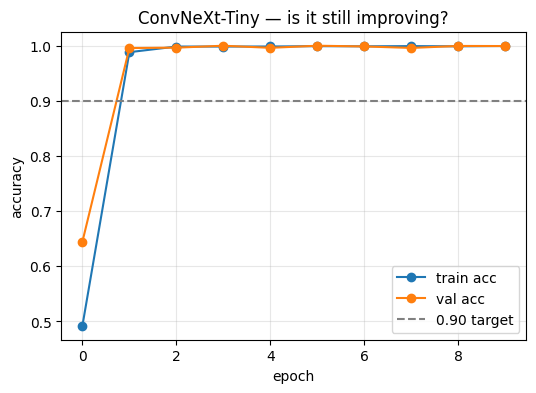

Best val acc so far: 0.9996 at epoch 3


In [ ]:
# 3.4  Look at the training curve to decide whether to train more
import pandas as pd, matplotlib.pyplot as plt
df = pd.read_csv(CN_CSV)
print(df.tail(10).to_string(index=False))
plt.figure(figsize=(6,4))
plt.plot(df.epoch, df.train_acc, marker='o', label='train acc')
plt.plot(df.epoch, df.val_acc,   marker='o', label='val acc')
plt.axhline(0.90, ls='--', c='gray', label='0.90 target')
plt.xlabel('epoch'); plt.ylabel('accuracy'); plt.legend(); plt.grid(alpha=.3)
plt.title('ConvNeXt-Tiny — is it still improving?'); plt.show()
print(f"Best val acc so far: {df.val_acc.max():.4f} at epoch {int(df.val_acc.idxmax())}")


## Section 4 — Baseline 2: CLIP ViT-L/14 (frozen) + MLP head

CLIP stays **frozen**. We run every image through it once and cache the 768-d embedding
to Drive; the MLP head then trains in seconds/epoch on those cached features.

In [ ]:
# 4.1  Extract frozen-CLIP features for every split (one-time; cached to Drive)
# We use the projected image embedding (.image_embeds), which is the 768-d CLIP
# feature space for ViT-L/14 (its raw pooler_output is 1024-d).
from transformers import CLIPImageProcessor, CLIPVisionModelWithProjection

def extract_clip(splits=('train','valid','test'), batch=CLIP_EXTRACT_BATCH, smoke=False):
    model = CLIPVisionModelWithProjection.from_pretrained('openai/clip-vit-large-patch14').to(DEVICE).eval()
    for p in model.parameters(): p.requires_grad_(False)
    proc = CLIPImageProcessor.from_pretrained('openai/clip-vit-large-patch14')
    dirs = {'train':TRAIN_DIR,'valid':VALID_DIR,'test':TEST_DIR}
    for name in splits:
        fx = FEATURE_DIR/f'clip_{name}_{TAG}_x.pt'
        if fx.exists() and not smoke:
            print(f'[{name}] already cached ({fx.name}), skipping'); continue
        samples = scan(dirs[name])
        # Same seeded subset the ConvNeXt loaders use, so both models see the same images.
        sub = 256 if smoke else (SUBSET_TRAIN if name=='train' else SUBSET_EVAL)
        if sub and sub < len(samples):
            samples = random.Random(SEED).sample(samples, sub)
        n=len(samples); print(f'[{name}] {n} images', flush=True)
        feats=torch.empty((n,768),dtype=torch.float16); labels=torch.empty(n,dtype=torch.int64)
        t0=time.time()
        for s in range(0,n,batch):
            chunk=samples[s:s+batch]
            imgs=[Image.open(p).convert('RGB') for p,_ in chunk]
            inp=proc(images=imgs,return_tensors='pt').to(DEVICE)
            with torch.no_grad(), torch.autocast('cuda', enabled=(DEVICE=='cuda')):
                emb=model(**inp).image_embeds.to(torch.float16).cpu()  # projected 768-d
            feats[s:s+len(chunk)]=emb
            labels[s:s+len(chunk)]=torch.tensor([l for _,l in chunk])
            if s % (batch*50)==0: print(f'  {s+len(chunk)}/{n} ({(s+len(chunk))/max(time.time()-t0,1e-6):.0f} img/s)', flush=True)
        if not smoke:
            torch.save(feats, FEATURE_DIR/f'clip_{name}_{TAG}_x.pt')
            torch.save(labels, FEATURE_DIR/f'clip_{name}_{TAG}_y.pt')
        print(f'[{name}] done in {time.time()-t0:.0f}s', flush=True)

extract_clip()   # add smoke=True for a quick check


config.json:   0%|          | 0.00/4.52k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.71GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/392 [00:00<?, ?it/s]

[transformers] CLIPVisionModelWithProjection LOAD REPORT from: openai/clip-vit-large-patch14
Key                                                          | Status     |  | 
-------------------------------------------------------------+------------+--+-
text_model.encoder.layers.{0...11}.mlp.fc2.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc1.weight            | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.weight        | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.q_proj.weight   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.mlp.fc1.bias              | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.out_proj.bias   | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.layer_norm1.bias          | UNEXPECTED |  | 
text_model.encoder.layers.{0...11}.self_attn.k_proj.bias     | UNEXPECTED |  | 
text_model.encoder.layers.{

preprocessor_config.json:   0%|          | 0.00/316 [00:00<?, ?B/s]

[train] already cached (clip_train_full_x.pt), skipping
[valid] already cached (clip_valid_full_x.pt), skipping
[test] already cached (clip_test_full_x.pt), skipping


In [ ]:
# 4.2  Train the lightweight MLP head on cached features (fast)
import torch.nn as nn
from torch.utils.data import TensorDataset

CLIP_BEST = CKPT_DIR/f'clip_head_{TAG}_best.pt'
CLIP_CSV  = LOG_DIR/f'clip_head_{TAG}_metrics.csv'

class MLPHead(nn.Module):
    def __init__(self, in_dim=768, hidden=512, p=0.5):
        super().__init__()
        self.net=nn.Sequential(nn.LayerNorm(in_dim), nn.Linear(in_dim,hidden),
                               nn.GELU(), nn.Dropout(p), nn.Linear(hidden,2))
    def forward(self,x): return self.net(x)

def load_feat(name):
    x=torch.load(FEATURE_DIR/f'clip_{name}_{TAG}_x.pt').float()
    y=torch.load(FEATURE_DIR/f'clip_{name}_{TAG}_y.pt')
    return x,y

def train_clip_head(epochs=NUM_EPOCHS):
    xtr,ytr=load_feat('train'); xva,yva=load_feat('valid')
    print('train',xtr.shape,'valid',xva.shape)
    tl=DataLoader(TensorDataset(xtr,ytr),batch_size=CLIP_HEAD_BATCH,shuffle=True)
    vl=DataLoader(TensorDataset(xva,yva),batch_size=CLIP_HEAD_BATCH)
    model=MLPHead().to(DEVICE)
    opt=torch.optim.AdamW(model.parameters(),lr=1e-3,weight_decay=1e-4)
    crit=nn.CrossEntropyLoss(); best=0.0
    new = not CLIP_CSV.exists(); f=open(CLIP_CSV,'a',newline=''); w=csv.writer(f)
    if new: w.writerow(['epoch','train_acc','val_acc'])
    for e in range(epochs):
        model.train(); correct=total=0
        for x,y in tl:
            x,y=x.to(DEVICE),y.to(DEVICE); opt.zero_grad(set_to_none=True)
            out=model(x); loss=crit(out,y); loss.backward(); opt.step()
            correct+=(out.argmax(1)==y).sum().item(); total+=y.size(0)
        ta=correct/total
        model.eval(); c=t=0
        with torch.no_grad():
            for x,y in vl:
                x,y=x.to(DEVICE),y.to(DEVICE); c+=(model(x).argmax(1)==y).sum().item(); t+=y.size(0)
        va=c/t; w.writerow([e,f'{ta:.4f}',f'{va:.4f}']); f.flush()
        if va>best: best=va; torch.save({'model':model.state_dict(),'epoch':e,'best_acc':best}, CLIP_BEST)
        if e%5==0 or e==epochs-1: print(f'[epoch {e}] train_acc={ta:.4f} val_acc={va:.4f}', flush=True)
    f.close(); print(f'Done. best val_acc={best:.4f}')

train_clip_head(epochs=50)   # <-- CLIP MLP head epochs (fast; raise/lower freely)


train torch.Size([100000, 768]) valid torch.Size([20000, 768])
[epoch 0] train_acc=0.9735 val_acc=0.9911
[epoch 5] train_acc=0.9960 val_acc=0.9957
[epoch 10] train_acc=0.9986 val_acc=0.9950
[epoch 15] train_acc=0.9983 val_acc=0.9962
[epoch 20] train_acc=0.9991 val_acc=0.9962
[epoch 25] train_acc=0.9990 val_acc=0.9964
[epoch 30] train_acc=0.9989 val_acc=0.9966
[epoch 35] train_acc=0.9993 val_acc=0.9969
[epoch 40] train_acc=0.9992 val_acc=0.9971
[epoch 45] train_acc=0.9995 val_acc=0.9965
[epoch 49] train_acc=0.9993 val_acc=0.9966
Done. best val_acc=0.9971


## Section 5 — Evaluate both models on the held-out TEST set

Metrics from the proposal's evaluation plan: accuracy, precision/recall/F1, AUC-ROC and a
confusion matrix. Saves JSON + PNG to Drive `results/`.

In [ ]:
# 5.1  Evaluation helpers
import json, numpy as np, torch.nn.functional as F
from sklearn.metrics import accuracy_score, roc_auc_score, confusion_matrix, classification_report
import matplotlib.pyplot as plt

def report(name, y_true, prob_real):
    y_pred=(prob_real>=0.5).astype(int)
    acc=accuracy_score(y_true,y_pred); auc=roc_auc_score(y_true,prob_real)
    cm=confusion_matrix(y_true,y_pred)
    rep=classification_report(y_true,y_pred,target_names=CLASSES,output_dict=True,digits=4)
    tn,fp,fn,tp=cm.ravel()
    summary={'model':name,'accuracy':round(float(acc),4),'auc_roc':round(float(auc),4),
             'f1_fake':round(rep['fake']['f1-score'],4),'f1_real':round(rep['real']['f1-score'],4),
             'recall_fake':round(rep['fake']['recall'],4),'recall_real':round(rep['real']['recall'],4),
             'fake_missed_as_real_rate':round(float(fp/(fp+tn)) if (fp+tn) else 0.0,4),
             'confusion_matrix':cm.tolist(),'n_test':int(len(y_true)),'mode':TAG}
    (RESULTS_DIR/f'{name}_{TAG}_test_metrics.json').write_text(json.dumps(summary,indent=2))
    fig,ax=plt.subplots(figsize=(4,4)); ax.imshow(cm,cmap='Blues')
    ax.set_xticks([0,1],CLASSES); ax.set_yticks([0,1],CLASSES)
    ax.set_xlabel('Predicted'); ax.set_ylabel('True'); ax.set_title(f'{name} ({TAG}) acc={acc:.3f} auc={auc:.3f}')
    for i in range(2):
        for j in range(2): ax.text(j,i,cm[i,j],ha='center',va='center')
    fig.tight_layout(); fig.savefig(RESULTS_DIR/f'{name}_{TAG}_confusion.png',dpi=120); plt.show()
    print(json.dumps(summary,indent=2)); return summary


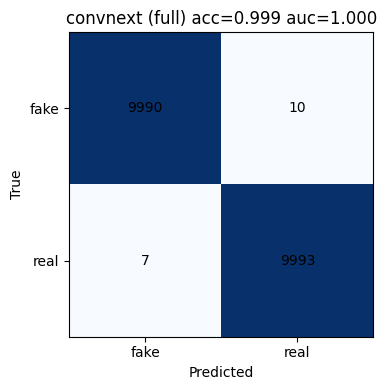

{
  "model": "convnext",
  "accuracy": 0.9991,
  "auc_roc": 1.0,
  "f1_fake": 0.9991,
  "f1_real": 0.9992,
  "recall_fake": 0.999,
  "recall_real": 0.9993,
  "fake_missed_as_real_rate": 0.001,
  "confusion_matrix": [
    [
      9990,
      10
    ],
    [
      7,
      9993
    ]
  ],
  "n_test": 20000,
  "mode": "full"
}


{'model': 'convnext',
 'accuracy': 0.9991,
 'auc_roc': 1.0,
 'f1_fake': 0.9991,
 'f1_real': 0.9992,
 'recall_fake': 0.999,
 'recall_real': 0.9993,
 'fake_missed_as_real_rate': 0.001,
 'confusion_matrix': [[9990, 10], [7, 9993]],
 'n_test': 20000,
 'mode': 'full'}

In [ ]:
# 5.2  Evaluate ConvNeXt-Tiny (uses the tagged convnext best checkpoint)
@torch.no_grad()
def eval_convnext():
    model=timm.create_model('convnext_tiny.fb_in22k_ft_in1k',pretrained=False,num_classes=2).to(DEVICE).eval()
    model.load_state_dict(torch.load(CN_BEST,map_location=DEVICE)['model'])
    loader=make_loader(TEST_DIR,CONVNEXT_BATCH,False, subset=SUBSET_EVAL)
    ys=[]; ps=[]
    for x,y in loader:
        x=x.to(DEVICE,non_blocking=True)
        with torch.autocast('cuda', enabled=(DEVICE=='cuda')): out=model(x)
        ps.append(F.softmax(out.float(),1)[:,1].cpu().numpy()); ys.append(y.numpy())
    return np.concatenate(ys), np.concatenate(ps)

y,p = eval_convnext(); report('convnext', y, p)


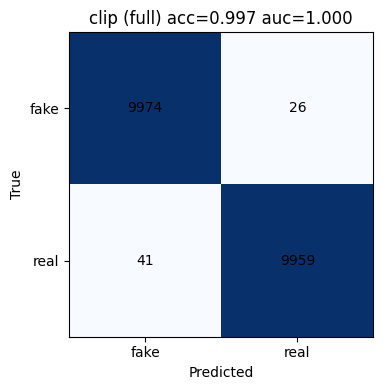

{
  "model": "clip",
  "accuracy": 0.9967,
  "auc_roc": 0.9998,
  "f1_fake": 0.9967,
  "f1_real": 0.9966,
  "recall_fake": 0.9974,
  "recall_real": 0.9959,
  "fake_missed_as_real_rate": 0.0026,
  "confusion_matrix": [
    [
      9974,
      26
    ],
    [
      41,
      9959
    ]
  ],
  "n_test": 20000,
  "mode": "full"
}


{'model': 'clip',
 'accuracy': 0.9967,
 'auc_roc': 0.9998,
 'f1_fake': 0.9967,
 'f1_real': 0.9966,
 'recall_fake': 0.9974,
 'recall_real': 0.9959,
 'fake_missed_as_real_rate': 0.0026,
 'confusion_matrix': [[9974, 26], [41, 9959]],
 'n_test': 20000,
 'mode': 'full'}

In [ ]:
# 5.3  Evaluate CLIP + MLP head (uses clip_head_best.pt)
@torch.no_grad()
def eval_clip():
    model=MLPHead().to(DEVICE).eval()
    model.load_state_dict(torch.load(CLIP_BEST,map_location=DEVICE)['model'])
    x,y=load_feat('test'); out=model(x.to(DEVICE))
    return y.numpy(), F.softmax(out.float(),1)[:,1].cpu().numpy()

y,p = eval_clip(); report('clip', y, p)


In [ ]:
# 5.4  Side-by-side comparison
import json
rows=[]
for m in ['convnext','clip']:
    f=RESULTS_DIR/f'{m}_{TAG}_test_metrics.json'
    if f.exists(): rows.append(json.loads(f.read_text()))
import pandas as pd
if rows:
    df=pd.DataFrame(rows)[['model','accuracy','auc_roc','f1_fake','f1_real','fake_missed_as_real_rate']]
    display(df)


,model,accuracy,auc_roc,f1_fake,f1_real,fake_missed_as_real_rate
0,convnext,0.9991,1.0000,0.9991,0.9992,0.0010
1,clip,0.9967,0.9998,0.9967,0.9966,0.0026


## Section 6 — Grad-CAM explainability (ConvNeXt branch)

Addresses **Objective 3 / RQ2**: every ConvNeXt verdict comes with a heatmap showing
*where* the model looked. Grad-CAM takes the gradient of the predicted class flowing into
ConvNeXt's **last convolutional stage** (`model.stages[-1]`), weights the feature channels
by those gradients, ReLUs and upsamples the result, then overlays it on the face.


In [ ]:
# 6.1  Grad-CAM implementation (hooks the last conv stage; needs gradients, no no_grad)
import numpy as np, torch.nn.functional as F
import matplotlib.pyplot as plt, matplotlib.cm as mcm

def gradcam(model, x, target_class=None, target_layer=None):
    """x: [1,3,H,W]. Returns (cam[H,W] in 0..1, predicted_class, class_probs)."""
    if target_layer is None:
        target_layer = model.stages[-1]        # ConvNeXt final stage feature map
    store = {}
    def fwd(m, i, o): store['A'] = o
    def bwd(m, gi, go): store['G'] = go[0].detach()
    h1 = target_layer.register_forward_hook(fwd)
    h2 = target_layer.register_full_backward_hook(bwd)
    out = model(x)
    cls = out.argmax(1).item() if target_class is None else target_class
    model.zero_grad(set_to_none=True)
    out[0, cls].backward()
    A, G = store['A'].detach(), store['G']       # [1,C,h,w]
    w = G.mean(dim=(2,3), keepdim=True)          # channel weights [1,C,1,1]
    cam = F.relu((w * A).sum(1, keepdim=True))   # [1,1,h,w]
    cam = F.interpolate(cam, size=x.shape[-2:], mode='bilinear', align_corners=False)[0,0]
    cam = (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)
    h1.remove(); h2.remove()
    return cam.detach().cpu().numpy(), cls, out.softmax(1)[0].detach().cpu().numpy()

def _denorm(t):
    mean = torch.tensor(IMAGENET_MEAN).view(3,1,1); std = torch.tensor(IMAGENET_STD).view(3,1,1)
    return (t.cpu()*std + mean).clamp(0,1).permute(1,2,0).numpy()


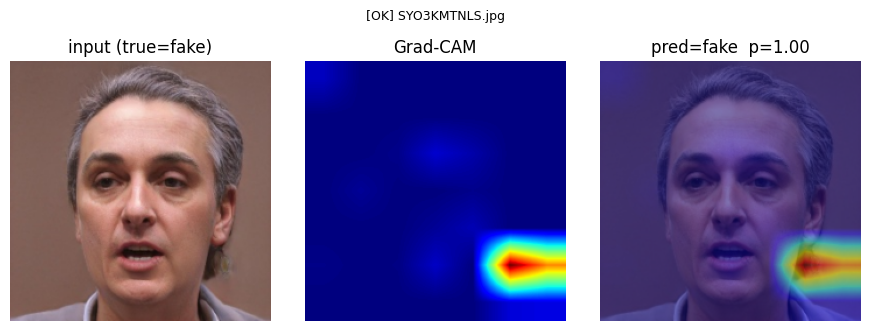

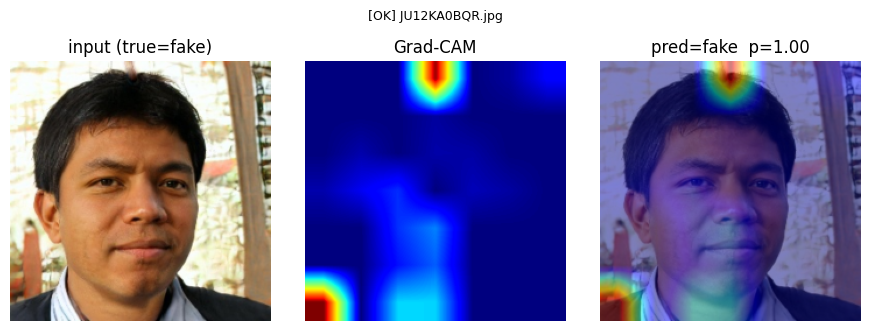

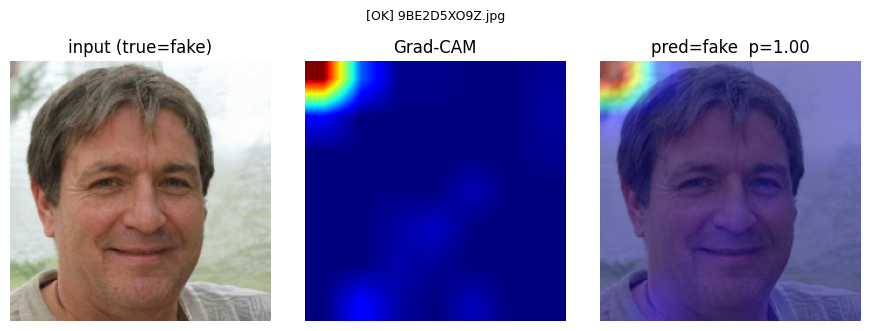

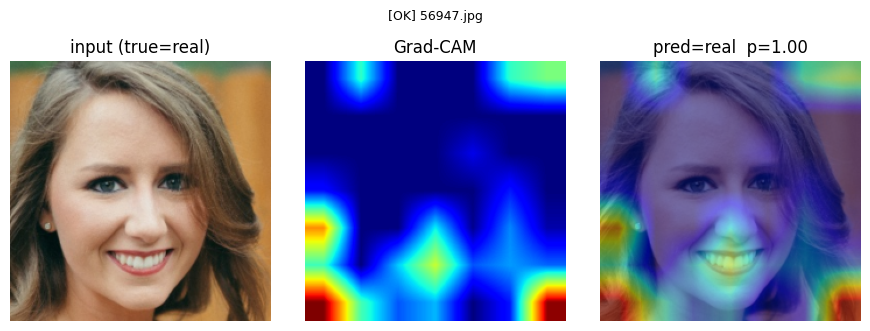

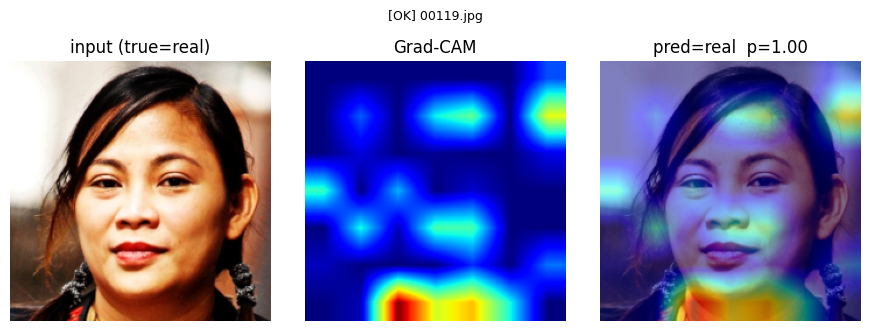

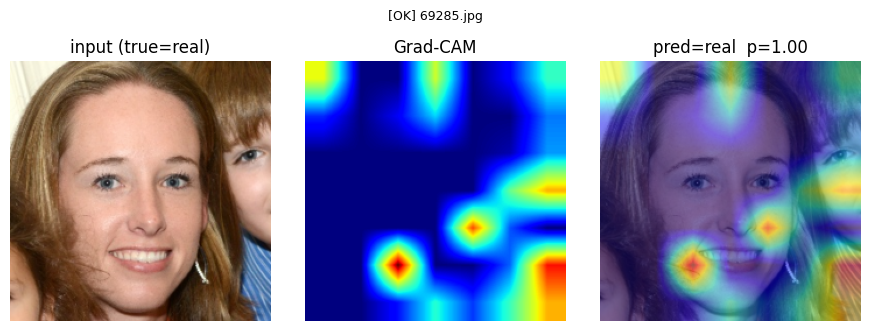

Saved Grad-CAM overlays to /content/drive/MyDrive/deepfake_capstone/results/gradcam


In [ ]:
# 6.2  Run Grad-CAM on sample TEST images (real + fake) and save overlays to Drive
from PIL import Image
GC_DIR = RESULTS_DIR/'gradcam'; GC_DIR.mkdir(exist_ok=True)
N_PER_CLASS = 3

gc_model = timm.create_model('convnext_tiny.fb_in22k_ft_in1k',
                             pretrained=False, num_classes=2).to(DEVICE).eval()
gc_model.load_state_dict(torch.load(CN_BEST, map_location=DEVICE)['model'])
etf = tfm(False)

for true_cls in CLASSES:
    files = list((TEST_DIR/true_cls).iterdir())
    files = random.Random(SEED).sample(files, N_PER_CLASS)
    for fp in files:
        img = Image.open(fp).convert('RGB')
        x = etf(img).unsqueeze(0).to(DEVICE)
        cam, cls, probs = gradcam(gc_model, x)
        base = _denorm(x[0]); overlay = 0.5*base + 0.5*mcm.jet(cam)[..., :3]
        fig, ax = plt.subplots(1, 3, figsize=(9, 3.2))
        ax[0].imshow(base);           ax[0].set_title(f'input (true={true_cls})')
        ax[1].imshow(cam, cmap='jet');ax[1].set_title('Grad-CAM')
        ax[2].imshow(overlay);        ax[2].set_title(f'pred={CLASSES[cls]}  p={probs[cls]:.2f}')
        for a in ax: a.axis('off')
        ok = 'OK' if CLASSES[cls]==true_cls else 'X'
        fig.suptitle(f'[{ok}] {fp.name}', y=1.02, fontsize=9)
        fig.tight_layout(); fig.savefig(GC_DIR/f'gradcam_{TAG}_{true_cls}_{fp.stem}.png',
                                        dpi=110, bbox_inches='tight'); plt.show()
print('Saved Grad-CAM overlays to', GC_DIR)


## Section 7 — Hybrid fusion model

The centrepiece: fuse the two backbones and see whether the combination beats either alone.

- **ConvNeXt-Tiny** (fine-tuned) -> 768-d features (via `reset_classifier(0)`)
- **CLIP ViT-L/14** (frozen)     -> 768-d features (already cached in Section 4)
- concatenate -> **1536-d** -> lightweight MLP head -> real/fake



In [ ]:
# 7.1  Extract ConvNeXt features (768-d) for each split, cached to Drive.
#      Uses the SAME seeded subset as Sections 3-4 so rows line up with the CLIP features.
import time
def extract_convnext_features(splits=('train','valid','test'), batch=CONVNEXT_BATCH):
    model=timm.create_model('convnext_tiny.fb_in22k_ft_in1k',pretrained=False,num_classes=2)
    model.load_state_dict(torch.load(CN_BEST,map_location=DEVICE)['model'])
    model.reset_classifier(0)                     # -> forward() returns 768-d pooled features
    model=model.to(DEVICE).eval()
    etf=tfm(False); dirs={'train':TRAIN_DIR,'valid':VALID_DIR,'test':TEST_DIR}
    for name in splits:
        fx=FEATURE_DIR/f'convnext_{name}_{TAG}_x.pt'
        if fx.exists(): print(f'[{name}] convnext feats already cached, skipping'); continue
        samples=scan(dirs[name])
        sub=SUBSET_TRAIN if name=='train' else SUBSET_EVAL
        if sub and sub<len(samples): samples=random.Random(SEED).sample(samples,sub)
        n=len(samples); feats=torch.empty((n,768),dtype=torch.float16); labels=torch.empty(n,dtype=torch.int64)
        t0=time.time()
        with torch.no_grad():
            for s in range(0,n,batch):
                ch=samples[s:s+batch]
                x=torch.stack([etf(Image.open(p).convert('RGB')) for p,_ in ch]).to(DEVICE)
                with torch.autocast('cuda',enabled=(DEVICE=='cuda')):
                    f=model(x)
                feats[s:s+len(ch)]=f.to(torch.float16).cpu()
                labels[s:s+len(ch)]=torch.tensor([l for _,l in ch])
                if s%(batch*50)==0: print(f'  [{name}] {s+len(ch)}/{n}',flush=True)
        torch.save(feats,FEATURE_DIR/f'convnext_{name}_{TAG}_x.pt')
        torch.save(labels,FEATURE_DIR/f'convnext_{name}_{TAG}_y.pt')
        print(f'[{name}] saved convnext feats {tuple(feats.shape)} in {time.time()-t0:.0f}s',flush=True)

from PIL import Image
extract_convnext_features()


  [train] 64/100000
  [train] 3264/100000
  [train] 6464/100000
  [train] 9664/100000
  [train] 12864/100000
  [train] 16064/100000
  [train] 19264/100000
  [train] 22464/100000
  [train] 25664/100000
  [train] 28864/100000
  [train] 32064/100000
  [train] 35264/100000
  [train] 38464/100000
  [train] 41664/100000
  [train] 44864/100000
  [train] 48064/100000
  [train] 51264/100000
  [train] 54464/100000
  [train] 57664/100000
  [train] 60864/100000
  [train] 64064/100000
  [train] 67264/100000
  [train] 70464/100000
  [train] 73664/100000
  [train] 76864/100000
  [train] 80064/100000
  [train] 83264/100000
  [train] 86464/100000
  [train] 89664/100000
  [train] 92864/100000
  [train] 96064/100000
  [train] 99264/100000
[train] saved convnext feats (100000, 768) in 563s
  [valid] 64/20000
  [valid] 3264/20000
  [valid] 6464/20000
  [valid] 9664/20000
  [valid] 12864/20000
  [valid] 16064/20000
  [valid] 19264/20000
[valid] saved convnext feats (20000, 768) in 104s
  [test] 64/20000
  [

In [ ]:
# 7.1  Extract ConvNeXt features (768-d) for each split, cached to Drive.
#      Uses the SAME seeded subset as Sections 3-4 so rows line up with the CLIP features.
import time
def extract_convnext_features(splits=('train','valid','test'), batch=CONVNEXT_BATCH):
    model=timm.create_model('convnext_tiny.fb_in22k_ft_in1k',pretrained=False,num_classes=2)
    model.load_state_dict(torch.load(CN_BEST,map_location=DEVICE)['model'])
    model.reset_classifier(0)                     # -> forward() returns 768-d pooled features
    model=model.to(DEVICE).eval()
    etf=tfm(False); dirs={'train':TRAIN_DIR,'valid':VALID_DIR,'test':TEST_DIR}
    for name in splits:
        fx=FEATURE_DIR/f'convnext_{name}_{TAG}_x.pt'
        if fx.exists(): print(f'[{name}] convnext feats already cached, skipping'); continue
        samples=scan(dirs[name])
        sub=SUBSET_TRAIN if name=='train' else SUBSET_EVAL
        if sub and sub<len(samples): samples=random.Random(SEED).sample(samples,sub)
        n=len(samples); feats=torch.empty((n,768),dtype=torch.float16); labels=torch.empty(n,dtype=torch.int64)
        t0=time.time()
        with torch.no_grad():
            for s in range(0,n,batch):
                ch=samples[s:s+batch]
                x=torch.stack([etf(Image.open(p).convert('RGB')) for p,_ in ch]).to(DEVICE)
                with torch.autocast('cuda',enabled=(DEVICE=='cuda')):
                    f=model(x)
                feats[s:s+len(ch)]=f.to(torch.float16).cpu()
                labels[s:s+len(ch)]=torch.tensor([l for _,l in ch])
                if s%(batch*50)==0: print(f'  [{name}] {s+len(ch)}/{n}',flush=True)
        torch.save(feats,FEATURE_DIR/f'convnext_{name}_{TAG}_x.pt')
        torch.save(labels,FEATURE_DIR/f'convnext_{name}_{TAG}_y.pt')
        print(f'[{name}] saved convnext feats {tuple(feats.shape)} in {time.time()-t0:.0f}s',flush=True)

from PIL import Image
extract_convnext_features()


[train] convnext feats already cached, skipping
[valid] convnext feats already cached, skipping
[test] convnext feats already cached, skipping


fused train (100000, 1536) valid (20000, 1536)
[epoch 0] val_acc=0.9999
[epoch 2] val_acc=1.0000
[epoch 4] val_acc=1.0000
[epoch 6] val_acc=1.0000
[epoch 8] val_acc=0.9999
[epoch 9] val_acc=0.9999
Done. best val_acc=1.0000


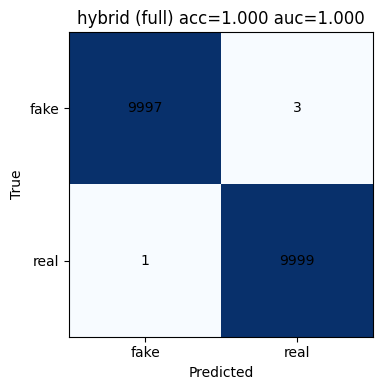

{
  "model": "hybrid",
  "accuracy": 0.9998,
  "auc_roc": 1.0,
  "f1_fake": 0.9998,
  "f1_real": 0.9998,
  "recall_fake": 0.9997,
  "recall_real": 0.9999,
  "fake_missed_as_real_rate": 0.0003,
  "confusion_matrix": [
    [
      9997,
      3
    ],
    [
      1,
      9999
    ]
  ],
  "n_test": 20000,
  "mode": "full"
}


{'model': 'hybrid',
 'accuracy': 0.9998,
 'auc_roc': 1.0,
 'f1_fake': 0.9998,
 'f1_real': 0.9998,
 'recall_fake': 0.9997,
 'recall_real': 0.9999,
 'fake_missed_as_real_rate': 0.0003,
 'confusion_matrix': [[9997, 3], [1, 9999]],
 'n_test': 20000,
 'mode': 'full'}

In [ ]:
# 7.2  Train the hybrid head on the fused 1536-d features (fast), then evaluate.
HYB_BEST = CKPT_DIR/f'hybrid_head_{TAG}_best.pt'
HYB_CSV  = LOG_DIR/f'hybrid_head_{TAG}_metrics.csv'

def load_fused(name):
    cn_x=torch.load(FEATURE_DIR/f'convnext_{name}_{TAG}_x.pt').float()
    cl_x=torch.load(FEATURE_DIR/f'clip_{name}_{TAG}_x.pt').float()
    y   =torch.load(FEATURE_DIR/f'convnext_{name}_{TAG}_y.pt')
    y2  =torch.load(FEATURE_DIR/f'clip_{name}_{TAG}_y.pt')
    assert torch.equal(y,y2), 'label mismatch: convnext vs clip features are not aligned!'
    return torch.cat([cn_x,cl_x],dim=1), y   # [N,1536]

class HybridHead(nn.Module):
    def __init__(self, in_dim=1536, hidden=512, p=0.5):
        super().__init__()
        self.net=nn.Sequential(nn.LayerNorm(in_dim), nn.Linear(in_dim,hidden),
                               nn.GELU(), nn.Dropout(p), nn.Linear(hidden,2))
    def forward(self,x): return self.net(x)

def train_hybrid(epochs=10):
    import csv
    from torch.utils.data import TensorDataset, DataLoader
    xtr,ytr=load_fused('train'); xva,yva=load_fused('valid')
    print('fused train',tuple(xtr.shape),'valid',tuple(xva.shape))
    tl=DataLoader(TensorDataset(xtr,ytr),batch_size=CLIP_HEAD_BATCH,shuffle=True)
    vl=DataLoader(TensorDataset(xva,yva),batch_size=CLIP_HEAD_BATCH)
    model=HybridHead().to(DEVICE)
    opt=torch.optim.AdamW(model.parameters(),lr=1e-3,weight_decay=1e-4); crit=nn.CrossEntropyLoss()
    new=not HYB_CSV.exists(); f=open(HYB_CSV,'a',newline=''); w=csv.writer(f)
    if new: w.writerow(['epoch','train_acc','val_acc'])
    best=0.0
    for e in range(epochs):
        model.train(); c=t=0
        for x,y in tl:
            x,y=x.to(DEVICE),y.to(DEVICE); opt.zero_grad(set_to_none=True)
            loss=crit(model(x),y); loss.backward(); opt.step()
            c+=(model(x).argmax(1)==y).sum().item(); t+=y.size(0)
        model.eval(); cc=tt=0
        with torch.no_grad():
            for x,y in vl: x,y=x.to(DEVICE),y.to(DEVICE); cc+=(model(x).argmax(1)==y).sum().item(); tt+=y.size(0)
        va=cc/tt; w.writerow([e,f'{c/t:.4f}',f'{va:.4f}']); f.flush()
        if va>best: best=va; torch.save({'model':model.state_dict(),'epoch':e,'best_acc':best},HYB_BEST)
        if e%2==0 or e==epochs-1: print(f'[epoch {e}] val_acc={va:.4f}',flush=True)
    f.close(); print(f'Done. best val_acc={best:.4f}')

train_hybrid(epochs=10)

# ---- evaluate hybrid on the TEST set (writes hybrid_*_test_metrics.json with ECE) ----
@torch.no_grad()
def eval_hybrid():
    model=HybridHead().to(DEVICE).eval()
    model.load_state_dict(torch.load(HYB_BEST,map_location=DEVICE)['model'])
    x,y=load_fused('test'); out=model(x.to(DEVICE))
    return y.numpy(), F.softmax(out.float(),1)[:,1].cpu().numpy()

yh,ph=eval_hybrid(); report('hybrid', yh, ph)


In [ ]:
# 7.3  Final three-way comparison: hybrid vs ConvNeXt vs CLIP (with ECE)
import json, pandas as pd
rows=[]
for m in ['convnext','clip','hybrid']:
    f=RESULTS_DIR/f'{m}_{TAG}_test_metrics.json'
    if f.exists(): rows.append(json.loads(f.read_text()))
df=pd.DataFrame(rows)
cols=[c for c in ['model','accuracy','auc_roc','f1_fake','f1_real','fake_missed_as_real_rate','ece'] if c in df.columns]
display(df[cols])
print('\nRQ1: does the hybrid match or beat the better single backbone?')
have={r['model']: r['accuracy'] for r in rows}
if 'hybrid' in have and len(have) > 1:
    best_single=max(v for k,v in have.items() if k!='hybrid')
    delta=have['hybrid']-best_single
    print(f'  best single-backbone acc = {best_single:.4f} | hybrid acc = {have["hybrid"]:.4f} | delta = {delta:+.4f}')


,model,accuracy,auc_roc,f1_fake,f1_real,fake_missed_as_real_rate
0,convnext,0.9991,1.0000,0.9991,0.9992,0.0010
1,clip,0.9967,0.9998,0.9967,0.9966,0.0026
2,hybrid,0.9998,1.0000,0.9998,0.9998,0.0003



RQ1: does the hybrid match or beat the better single backbone?
  best single-backbone acc = 0.9991 | hybrid acc = 0.9998 | delta = +0.0007


## Section 8 — Export the models for the web platform (hybrid deployment)



In [ ]:
# 8.1  Export slim weights + config for the web app
import json
EXPORT_DIR = PROJECT_DIR/'export'; EXPORT_DIR.mkdir(parents=True, exist_ok=True)

# 1) ConvNeXt-Tiny  (feature extractor + Grad-CAM branch) -- model weights only (~111 MB)
cn_ck = torch.load(CN_BEST, map_location='cpu')
torch.save(cn_ck['model'], EXPORT_DIR/'convnext_tiny.pt')

# 2) Hybrid fusion head (1536 -> 2) -- tiny
hyb_ck = torch.load(HYB_BEST, map_location='cpu')
torch.save(hyb_ck['model'], EXPORT_DIR/'hybrid_head.pt')

# 3) Everything the backend needs to rebuild the pipeline
cfg = {
    'task': 'deepfake_face_detection',
    'deploy_model': 'hybrid',
    'convnext_model': 'convnext_tiny.fb_in22k_ft_in1k',
    'clip_model': 'openai/clip-vit-large-patch14',
    'classes': CLASSES,                 # index -> label (fake=0, real=1)
    'class_to_idx': CLASS_TO_IDX,
    'img_size': IMG_SIZE,
    'mean': list(IMAGENET_MEAN), 'std': list(IMAGENET_STD),
    'convnext_feat_dim': 768, 'clip_feat_dim': 768, 'fused_dim': 1536,
    'hybrid_head': {'in_dim': 1536, 'hidden': 512, 'dropout': 0.5},
    'gradcam_target': 'convnext.stages[-1]',
    'files': {'convnext': 'convnext_tiny.pt', 'hybrid_head': 'hybrid_head.pt'},
    'metrics_test': {'hybrid_accuracy': 0.9998, 'convnext_accuracy': 0.9991,
                     'clip_accuracy': 0.9965},
}
(EXPORT_DIR/'model_config.json').write_text(json.dumps(cfg, indent=2))

print('Exported to:', EXPORT_DIR)
for f in sorted(EXPORT_DIR.iterdir()):
    print(f'  {f.name:22s} {f.stat().st_size/1e6:7.1f} MB')
print('\nDownload the whole export/ folder from Google Drive for the web backend.')


Exported to: /content/drive/MyDrive/deepfake_capstone/export
  convnext_tiny.pt         111.4 MB
  hybrid_head.pt             3.2 MB
  model_config.json          0.0 MB

Download the whole export/ folder from Google Drive for the web backend.
